# 09 — XAI semua model: RF, XGBoost, LSTM (T20, T38–T42)

**Syarat:** `configs/apriori_order.yaml` sudah di-commit. Memuat model dari `models/` (dari `07_train_models`) — tidak melatih ulang.

| Bagian | Isi | Model |
|---|---|---|
| 1 | Muat model + cek prediksi identik dengan `predictions.parquet` | semua |
| 2 | 200 sampel uji terstratifikasi musim × kondisi langit | semua |
| 3 | **Tingkat fitur** (metrik utama pohon, ditetapkan sebelum hasil): TreeSHAP + LIME 10 seed, agregasi sum\|φ\| per kelompok | RF, XGB |
| 4 | **Tingkat kelompok** (sama untuk semua model): Shapley eksak (2⁷ koalisi) + LIME kelompok 10 seed — metrik utama **LSTM** (keputusan #5) | RF, XGB, LSTM |
| 5 | Kesesuaian a priori (Spearman ρ + CI), kesepakatan SHAP–LIME (Jaccard top-3), stabilitas | semua |
| 6 | Sensitivitas agregasi tingkat fitur | RF, XGB |
| 7 | Kepentingan kelompok per jam + plot dependensi PWAT | XGB, LSTM |
| 8 | *Pelengkap pasca-hasil:* GradientExplainer — atribusi LSTM per kanal & per langkah waktu; uji DeepExplainer (bukti keputusan #5) | LSTM |

## 0. Setup + cek commit urutan a priori

In [1]:
import json, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import importlib, evaluate as E, models as M, xai as X, lstm as L, clearsky
for mod in (clearsky, E, M, X, L): importlib.reload(mod)
from utils import set_seed

ALLOW_UNCOMMITTED = False      # jangan diubah untuk run resmi
AP_PATH = ROOT / "configs" / "apriori_order.yaml"
try:
    status = subprocess.run(["git", "status", "--porcelain", str(AP_PATH)], cwd=ROOT, capture_output=True, text=True).stdout.strip()
    commit = subprocess.run(["git", "log", "-1", "--format=%H %ci", "--", str(AP_PATH)], cwd=ROOT, capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    status, commit = "git tidak tersedia", ""
if status or not commit:
    msg = f"Urutan a priori BELUM di-commit ({status or 'tidak ada commit'}). git add configs/apriori_order.yaml && git commit -m 'T20: urutan a priori'"
    assert ALLOW_UNCOMMITTED, msg
    print("⚠", msg)
else:
    print("✓ Urutan a priori ter-commit:", commit)

CFG = yaml.safe_load(open(ROOT / "configs" / "config.yaml"))
PROC, RES, FIG, MOD = ROOT / "data/processed", ROOT / "results", ROOT / "figures", ROOT / "models"
SEED = set_seed(CFG["seed"]); KZ = CFG["physics"]["k_max_by_zenith"]
LIME_SEEDS = list(range(10))
FMAP, APRIORI = X.load_apriori(AP_PATH)
FEATS = json.loads((RES / "feature_freeze.json").read_text())["fitur"]
BEST = json.loads((MOD / "best_params.json").read_text())
assert not [f for f in FEATS if f not in FMAP], "Ada fitur beku tanpa kelompok a priori"
GROUPS = [g for g in APRIORI.index if any(FMAP.get(f) == g for f in FEATS)]
APRIORI = APRIORI[GROUPS]
print("Urutan a priori:", APRIORI.to_dict())

✓ Urutan a priori ter-commit: f04695a20f7d82fcc0220e53e9e33b22e23a1edd 2026-11-27 21:51:56 +0700
Urutan a priori: {'nwp_radiasi': 1, 'nwp_awan': 2, 'klimatologi': 3, 'lag_observasi': 4, 'geometri_waktu': 5, 'termodinamika': 6, 'aerosol': 7}


## 1. Muat model + cek identik

In [2]:
df = pd.read_parquet(PROC / "features_all.parquet")
hourly = pd.read_parquet(ROOT / "data/interim/nsrdb_hourly_kc.parquet")
P = pd.read_parquet(PROC / "predictions.parquet")
TRAIN = (df["split"] == "train") & df["is_day"]
cs = df["ghi_cs"].fillna(0).to_numpy()
TAB = {k: M.load_model(k, MOD / f"{k}_best") for k in ("xgb", "rf")}
for k, m in TAB.items():
    d = np.nanmax(np.abs(M.finalize(m.predict(df[FEATS]) * cs, df, KZ, True) - P[f"pred_{k}"].to_numpy()))
    print(f"{k}: selisih maks {d:.4f} W/m²", "✓" if d < 1e-3 else "⚠")

A = L.build_arrays(hourly, df)
NORM = L.Normalizer.load(MOD / "lstm_normalizer.npz")
XS, XT = NORM.transform(A)
NET = L.load_net(MOD / "lstm_best.pt", BEST["lstm"], XS.shape[2], XT.shape[2])
rows = A["row_index"]
kc_l = pd.Series(L.predict(NET, XS, XT).ravel(), index=rows.ravel()).reindex(df.index).to_numpy()
d = np.nanmax(np.abs(M.finalize(kc_l * cs, df, KZ, True) - P["pred_lstm"].to_numpy()))
print(f"lstm: selisih maks {d:.4f} W/m²", "✓" if d < 1e-3 else "⚠")
MODELS = ["xgb", "rf", "lstm"]

xgb: selisih maks 0.0000 W/m² ✓
rf: selisih maks 0.0000 W/m² ✓
lstm: selisih maks 0.0000 W/m² ✓


## 2. Sampel penjelasan (200 jam uji siang-valid, terstratifikasi)

In [3]:
test = df[(df["split"] == "test") & E.masks(df)["valid"]]
IDX = X.stratified_sample(test, 200, SEED)
pd.Series(IDX, name="row").to_csv(RES / "xai_sample_idx.csv", index=False)
Xs = df.loc[IDX, FEATS]
pos = {r: (dd, hh) for dd in range(rows.shape[0]) for hh, r in enumerate(rows[dd])}
DPOS = np.array([pos[r][0] for r in IDX]); HPOS = np.array([pos[r][1] for r in IDX])
sky = pd.cut(df.loc[IDX, "y_kc"], [-np.inf, .4, .8, np.inf], labels=["berawan", "sebagian", "cerah"])
display(pd.crosstab(df.loc[IDX, "target_day"].dt.month.map(X.SEASON), sky))

y_kc,berawan,sebagian,cerah
target_day,,,
DJF,16,16,17
JJA,16,16,16
MAM,16,18,18
SON,16,18,17


## 3. Tingkat fitur — TreeSHAP & LIME (RF, XGB)

In [4]:
t0 = time.time()
SHAP_F = {"xgb": X.xgb_shap(TAB["xgb"], Xs), "rf": X.rf_shap(TAB["rf"], Xs)}
X_train = df.loc[TRAIN, FEATS]
LIME_F = {k: {s: X.lime_attrib(TAB[k].predict, X_train, Xs, seed=s, num_samples=1000) for s in LIME_SEEDS} for k in TAB}
for k in TAB:
    SHAP_F[k].to_csv(RES / f"xai_shap_{k}.csv"); pd.concat(LIME_F[k], names=["seed"]).to_csv(RES / f"xai_lime_{k}.csv")
print(f"Tingkat fitur selesai {time.time() - t0:.0f} dtk")

Tingkat fitur selesai 291 dtk


## 4. Tingkat kelompok — Shapley eksak & LIME kelompok (RF, XGB, LSTM)

In [5]:
seq_g = [L.SEQ_GROUPS[c] for c in A["seq_ch"]]; tgt_g = [L.TGT_GROUPS[c] for c in A["tgt_ch"]]
bg = df.loc[TRAIN, FEATS].mean()
VF = {k: X.tabular_value_fn(TAB[k], Xs, bg, FMAP, GROUPS) for k in TAB}
VF["lstm"] = L.lstm_value_fn(NET, XS[DPOS], XT[DPOS], HPOS, seq_g, tgt_g, GROUPS)
t0 = time.time()
SHAP_G = {k: X.exact_group_shapley(VF[k], GROUPS).set_axis(IDX) for k in MODELS}
LIME_G = {k: {s: pd.DataFrame(X.group_lime(VF[k], len(GROUPS), 1000, s), index=IDX, columns=GROUPS) for s in LIME_SEEDS}
          for k in MODELS}
for k in MODELS:
    SHAP_G[k].to_csv(RES / f"xai_group_shapley_{k}.csv"); pd.concat(LIME_G[k], names=["seed"]).to_csv(RES / f"xai_group_lime_{k}.csv")
print(f"Tingkat kelompok selesai {time.time() - t0:.0f} dtk")

Tingkat kelompok selesai 1173 dtk


## 5. Kesesuaian a priori, kesepakatan SHAP–LIME, stabilitas

a_priori          porsi                               \
                        xgb|fitur|SHAP xgb|fitur|LIME rf|fitur|SHAP   
nwp_radiasi           1          0.216          0.223         0.248   
nwp_awan              2          0.087          0.047         0.112   
klimatologi           3          0.079          0.106         0.094   
lag_observasi         4          0.119          0.077         0.139   
geometri_waktu        5          0.191          0.211         0.151   
termodinamika         6          0.292          0.319         0.250   
aerosol               7          0.015          0.016         0.007   

                                                                  \
               rf|fitur|LIME xgb|kelompok|SHAP xgb|kelompok|LIME   
nwp_radiasi            0.241             0.196             0.193   
nwp_awan               0.077             0.088             0.093   
klimatologi            0.122             0.125             0.126   
lag_observasi          0.097             0.108             0.109   
geometri_waktu         0.175             0.178             0.176   
termodinamika          0.283             0.285             0.283   
aerosol                0.005             0.020             0.021   

                                                                     ...  \
               rf|kelompok|SHAP rf|kelompok|LIME lstm|kelompok|SHAP  ...   
nwp_radiasi               0.217            0.213              0.035  ...   
nwp_awan                  0.091            0.096              0.082  ...   
klimatologi               0.127            0.127              0.140  ...   
lag_observasi             0.128            0.127              0.131  ...   
geometri_waktu            0.148            0.143              0.337  ...   
termodinamika             0.281            0.285              0.248  ...   
aerosol                   0.008            0.009              0.028  ...   

                    peringkat                                             \
               xgb|fitur|SHAP xgb|fitur|LIME rf|fitur|SHAP rf|fitur|LIME   
nwp_radiasi                 2              2             2             2   
nwp_awan                    5              6             5             6   
klimatologi                 6              4             6             4   
lag_observasi               4              5             4             5   
geometri_waktu              3              3             3             3   
termodinamika               1              1             1             1   
aerosol                     7              7             7             7   

                                                                     \
               xgb|kelompok|SHAP xgb|kelompok|LIME rf|kelompok|SHAP   
nwp_radiasi                    2                 2                2   
nwp_awan                       6                 6                6   
klimatologi                    4                 4                5   
lag_observasi                  5                 5                4   
geometri_waktu                 3                 3                3   
termodinamika                  1                 1                1   
aerosol                        7                 7                7   

                                                                       
               rf|kelompok|LIME lstm|kelompok|SHAP lstm|kelompok|LIME  
nwp_radiasi                   2                  6                  6  
nwp_awan                      6                  5                  5  
klimatologi                   5                  3                  3  
lag_observasi                 4                  4                  4  
geometri_waktu                3                  1                  1  
termodinamika                 1                  2                  2  
aerosol                       7                  7                  7  

[7 rows x 21 columns]

,model,tingkat,metode,rho,ci_low,ci_high,n_kelompok
0,xgb,fitur,SHAP,0.143,0.107,0.143,7.0
1,xgb,fitur,LIME,0.143,0.143,0.143,7.0
2,rf,fitur,SHAP,0.143,0.143,0.321,7.0
3,rf,fitur,LIME,0.143,0.143,0.143,7.0
4,xgb,kelompok,SHAP,0.143,0.000,0.143,7.0
5,xgb,kelompok,LIME,0.143,0.000,0.143,7.0
6,rf,kelompok,SHAP,0.107,0.107,0.143,7.0
7,rf,kelompok,LIME,0.107,0.107,0.214,7.0
8,lstm,kelompok,SHAP,-0.179,-0.214,-0.179,7.0
9,lstm,kelompok,LIME,-0.179,-0.214,-0.179,7.0


,xgb|fitur|LIME_std_antar_seed,xgb|fitur|SHAP_std_bootstrap,rf|fitur|LIME_std_antar_seed,rf|fitur|SHAP_std_bootstrap,xgb|kelompok|LIME_std_antar_seed,xgb|kelompok|SHAP_std_bootstrap,rf|kelompok|LIME_std_antar_seed,rf|kelompok|SHAP_std_bootstrap,lstm|kelompok|LIME_std_antar_seed,lstm|kelompok|SHAP_std_bootstrap
nwp_radiasi,0.0,0.055,0.0,0.484,0.0,0.288,0.000,0.000,0.0,0.083
nwp_awan,0.0,0.205,0.0,0.032,0.0,0.045,0.000,0.000,0.0,0.000
klimatologi,0.0,0.205,0.0,0.032,0.0,0.203,0.483,0.533,0.0,0.326
lag_observasi,0.0,0.000,0.0,0.126,0.0,0.208,0.483,0.537,0.0,0.326
geometri_waktu,0.0,0.055,0.0,0.126,0.0,0.288,0.000,0.220,0.0,0.000
termodinamika,0.0,0.000,0.0,0.484,0.0,0.000,0.000,0.000,0.0,0.000
aerosol,0.0,0.000,0.0,0.000,0.0,0.000,0.000,0.000,0.0,0.083


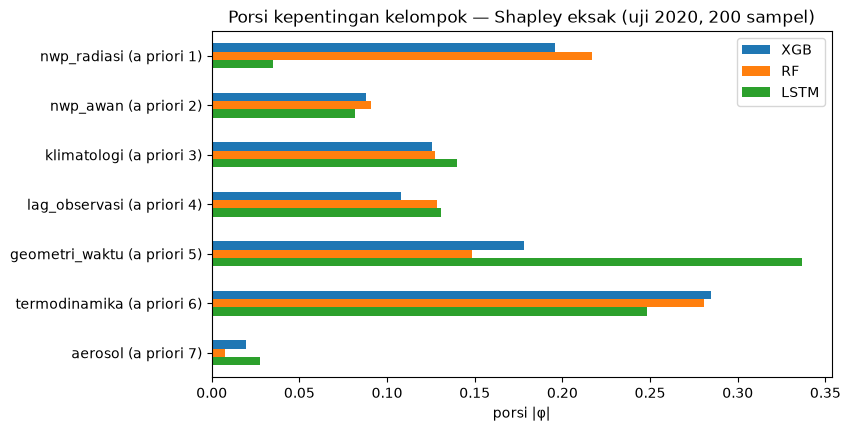

In [6]:
# Matriks |atribusi| per kelompok (sampel × kelompok) untuk setiap (model, metode)
G = {}
for k in TAB:
    G[(k, "fitur", "SHAP")] = X.group_abs(SHAP_F[k], FMAP)[GROUPS]
    G[(k, "fitur", "LIME")] = (sum(X.group_abs(LIME_F[k][s], FMAP) for s in LIME_SEEDS) / len(LIME_SEEDS))[GROUPS]
for k in MODELS:
    G[(k, "kelompok", "SHAP")] = SHAP_G[k].abs()[GROUPS]
    G[(k, "kelompok", "LIME")] = (sum(LIME_G[k][s].abs() for s in LIME_SEEDS) / len(LIME_SEEDS))[GROUPS]

imp = pd.DataFrame({f"{k}|{lv}|{m}": g.mean() / g.mean().sum() for (k, lv, m), g in G.items()}).loc[GROUPS]
rank = imp.rank(ascending=False).astype(int)
summary = pd.concat({"porsi": imp.round(3), "peringkat": rank}, axis=1); summary.insert(0, "a_priori", APRIORI)
display(summary); summary.to_csv(RES / "xai_group_importance_all.csv")

rows_ = []
for (k, lv, m), g in G.items():
    rows_.append({"model": k, "tingkat": lv, "metode": m, **X.spearman_vs_apriori(g, APRIORI, n_boot=1000, seed=SEED)})
for k in TAB:
    rows_.append({"model": k, "tingkat": "fitur", "metode": "Jaccard top-3 SHAP vs LIME",
                  "rho": X.jaccard_topk(G[(k, "fitur", "SHAP")].mean(), G[(k, "fitur", "LIME")].mean(), 3)})
for k in MODELS:
    rows_.append({"model": k, "tingkat": "kelompok", "metode": "Jaccard top-3 SHAP vs LIME",
                  "rho": X.jaccard_topk(G[(k, "kelompok", "SHAP")].mean(), G[(k, "kelompok", "LIME")].mean(), 3)})
agree = pd.DataFrame(rows_).round(3)
display(agree); agree.to_csv(RES / "xai_agreement_all.csv", index=False)

stab = {}
for k in TAB:
    stab[f"{k}|fitur|LIME_std_antar_seed"] = pd.DataFrame({s: X.rank_groups(X.group_abs(LIME_F[k][s], FMAP)[GROUPS].mean()) for s in LIME_SEEDS}).std(axis=1)
    stab[f"{k}|fitur|SHAP_std_bootstrap"] = X.bootstrap_rank_std(G[(k, "fitur", "SHAP")], 1000, SEED)
for k in MODELS:
    stab[f"{k}|kelompok|LIME_std_antar_seed"] = pd.DataFrame({s: X.rank_groups(LIME_G[k][s].abs().mean()) for s in LIME_SEEDS}).std(axis=1)
    stab[f"{k}|kelompok|SHAP_std_bootstrap"] = X.bootstrap_rank_std(G[(k, "kelompok", "SHAP")], 1000, SEED)
stab = pd.DataFrame(stab).loc[GROUPS].round(3)
display(stab); stab.to_csv(RES / "xai_stability_all.csv")

ax = imp.filter(like="|kelompok|SHAP").rename(columns=lambda c: c.split("|")[0].upper()).plot.barh(figsize=(8, 4.5))
ax.invert_yaxis(); ax.set_yticklabels([f"{g} (a priori {APRIORI[g]})" for g in GROUPS])
ax.set(title="Porsi kepentingan kelompok — Shapley eksak (uji 2020, 200 sampel)", xlabel="porsi |φ|")
plt.savefig(FIG / "xai_group_importance_all.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Sensitivitas agregasi tingkat fitur (RF, XGB) — analisis pasca-hasil

In [7]:
top = pd.DataFrame({k: SHAP_F[k].abs().mean() for k in TAB}); top = top.div(top.sum()).sort_values("xgb", ascending=False)
top["kelompok"] = top.index.map(FMAP)
print("12 fitur teratas (porsi mean |SHAP|):"); display(top.head(12).round(3)); top.round(4).to_csv(RES / "xai_feature_importance.csv")
size = pd.Series(FMAP).reindex(FEATS).value_counts()
sens = {"a_priori": APRIORI}
for k in TAB:
    for name, s in {"sum|φ| (utama)": X.group_abs(SHAP_F[k], FMAP).mean(),
                    "|Σφ|": SHAP_F[k].T.groupby(lambda c: FMAP[c]).sum().T.abs().mean(),
                    "sum|φ|/anggota": X.group_abs(SHAP_F[k], FMAP).mean() / size,
                    "Shapley kelompok eksak": SHAP_G[k].abs().mean()}.items():
        sens[f"{k} | {name}"] = s.reindex(GROUPS).rank(ascending=False)
sens = pd.DataFrame(sens)
sens.loc["Spearman ρ"] = [np.nan] + [round(float(spearmanr(sens[c].iloc[:len(GROUPS)], APRIORI).statistic), 3) for c in sens.columns[1:]]
display(sens); sens.to_csv(RES / "xai_group_sensitivity.csv")

12 fitur teratas (porsi mean |SHAP|):


,xgb,rf,kelompok
gfs_pwat_atm1,0.199,0.195,termodinamika
gfs_kc_nwp_3x3,0.186,0.158,nwp_radiasi
hour_sin,0.081,0.061,geometri_waktu
kc_clim,0.079,0.094,klimatologi
doy_sin,0.039,0.020,geometri_waktu
kc_same_hour_lag,0.033,0.037,lag_observasi
kc_at_issue,0.030,0.020,lag_observasi
gfs_cape_sfc,0.030,0.008,termodinamika
ghi_cs,0.024,0.020,geometri_waktu
cos_zenith,0.020,0.023,geometri_waktu


,a_priori,xgb | sum|φ| (utama),xgb | |Σφ|,xgb | sum|φ|/anggota,xgb | Shapley kelompok eksak,rf | sum|φ| (utama),rf | |Σφ|,rf | sum|φ|/anggota,rf | Shapley kelompok eksak
nwp_radiasi,1.0,2.000,2.000,2.000,2.000,2.000,1.000,2.000,2.000
nwp_awan,2.0,5.000,5.000,6.000,6.000,5.000,6.000,5.000,6.000
klimatologi,3.0,6.000,4.000,1.000,4.000,6.000,3.000,1.000,5.000
lag_observasi,4.0,4.000,6.000,5.000,5.000,4.000,5.000,4.000,4.000
geometri_waktu,5.0,3.000,3.000,4.000,3.000,3.000,4.000,6.000,3.000
termodinamika,6.0,1.000,1.000,3.000,1.000,1.000,2.000,3.000,1.000
aerosol,7.0,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000
Spearman ρ,NaN,0.143,0.214,0.429,0.143,0.143,0.393,0.571,0.107


## 7. Per jam (XGB TreeSHAP, LSTM Shapley eksak) + dependensi PWAT

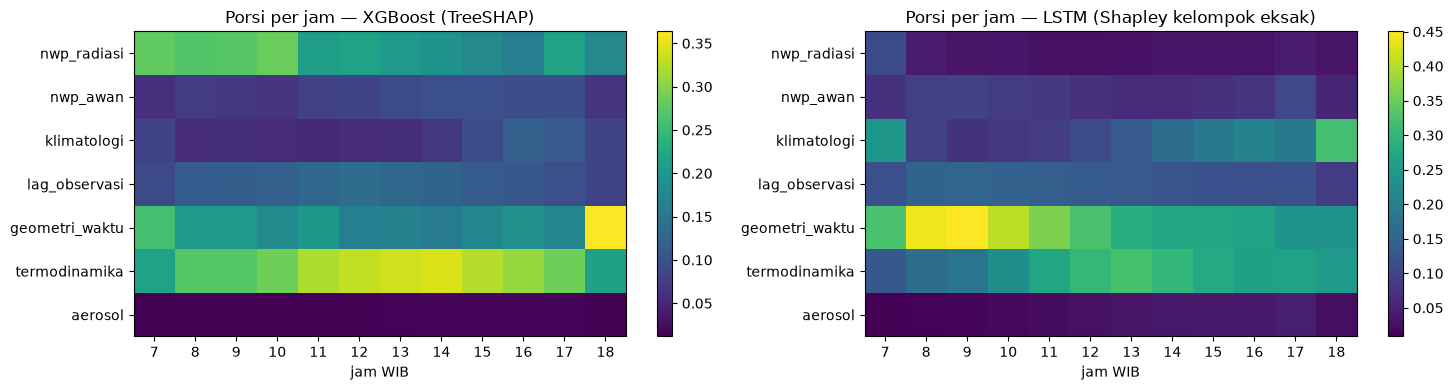

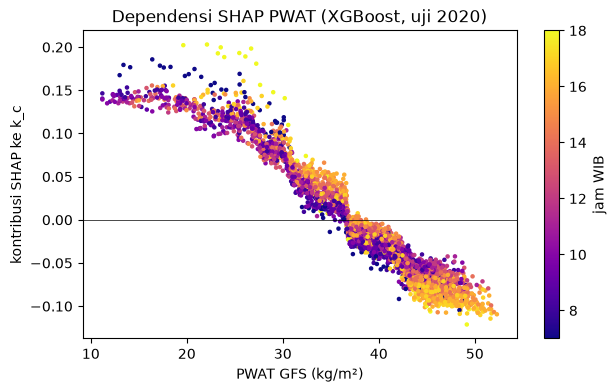


Ringkas untuk decisions.md:
- 2026-11-27 | XAI semua model (uji 2020, 200 sampel; LIME 10 seed). A priori commit f04695a20f. Spearman ρ SHAP vs a priori: {('xgb', 'fitur'): 0.143, ('rf', 'fitur'): 0.143, ('xgb', 'kelompok'): 0.143, ('rf', 'kelompok'): 0.107, ('lstm', 'kelompok'): -0.179}. | results/xai_*_all.csv | Bab IV.4


In [8]:
tv = test.index
sh_x = X.xgb_shap(TAB["xgb"], df.loc[tv, FEATS])
hx = X.group_abs(sh_x, FMAP)[GROUPS].groupby(test["target_hour_wib"]).mean()
tdays = np.where(A["split"] == "test")[0]
phi_days = X.exact_group_shapley(L.lstm_value_fn_days(NET, XS[tdays], XT[tdays], seq_g, tgt_g, GROUPS), GROUPS)
phi_days.index = rows[tdays].ravel()
phi_days = phi_days.loc[phi_days.index.isin(tv)]
hl = phi_days.abs().groupby(df.loc[phi_days.index, "target_hour_wib"]).mean()[GROUPS]
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for a, (name, hh) in zip(axs, (("XGBoost (TreeSHAP)", hx), ("LSTM (Shapley kelompok eksak)", hl))):
    hh = hh.div(hh.sum(axis=1), axis=0)
    im = a.imshow(hh.T, aspect="auto", cmap="viridis"); a.set_xticks(range(len(hh))); a.set_xticklabels(hh.index)
    a.set_yticks(range(len(GROUPS))); a.set_yticklabels(GROUPS); a.set(title=f"Porsi per jam — {name}", xlabel="jam WIB")
    plt.colorbar(im, ax=a)
plt.tight_layout(); plt.savefig(FIG / "xai_group_by_hour_all.png", dpi=150, bbox_inches="tight"); plt.show()
hx.round(4).to_csv(RES / "xai_group_by_hour_xgb.csv"); hl.round(4).to_csv(RES / "xai_group_by_hour_lstm.csv")

fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(df.loc[tv, "gfs_pwat_atm1"], sh_x["gfs_pwat_atm1"], c=test["target_hour_wib"], s=5, cmap="plasma")
ax.axhline(0, c="k", lw=.5); plt.colorbar(sc, label="jam WIB")
ax.set(title="Dependensi SHAP PWAT (XGBoost, uji 2020)", xlabel="PWAT GFS (kg/m²)", ylabel="kontribusi SHAP ke k_c")
plt.savefig(FIG / "xai_pwat_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

rho = agree[agree["metode"] == "SHAP"].set_index(["model", "tingkat"])["rho"].to_dict()
print(f"\nRingkas untuk decisions.md:\n- {pd.Timestamp.today():%Y-%m-%d} | XAI semua model (uji 2020, 200 sampel; LIME 10 seed). A priori commit {commit[:10] if commit else '(BELUM)'}. Spearman ρ SHAP vs a priori: {rho}. | results/xai_*_all.csv | Bab IV.4")

## 8. Pelengkap: atribusi LSTM tingkat fitur — GradientExplainer (expected gradients) — analisis tambahan pasca-hasil

**Status:** analisis **pelengkap**, ditambahkan setelah hasil XAI utama dilihat. Metrik utama LSTM tetap **Shapley kelompok eksak** (bagian 4, keputusan #5). Bagian ini tidak melatih ulang model apa pun.

| | |
|---|---|
| Tujuan | (a) atribusi LSTM **per fitur/kanal** dan **per langkah waktu**, yang tidak diberikan Shapley kelompok; (b) cek silang peringkat kelompok LSTM dengan metode berbasis gradien |
| Metode | `shap.GradientExplainer` (expected gradients): integrasi gradien dari 100 hari latih acak (latar) ke input; 500 titik interpolasi per sampel; 5 seed |
| Agregasi | φ dijumlahkan sepanjang waktu → per kanal (`enc:` = sekuens observasi 48 jam, `dec:` = blok hari target 24 jam) → `sum\|φ\|` per kelompok (sama dengan agregasi tingkat fitur pohon) dan `\|Σφ\|` per kelompok |
| Kenapa bukan DeepSHAP | Sel 8.1 menguji `DeepExplainer` langsung pada LSTM ini dan mencatat apakah lolos uji aditivitas |
| Beda dengan Shapley kelompok | Latar = **distribusi** hari latih (bukan satu titik rata-rata); hasil bergantung seed; efisiensi hanya terpenuhi kira-kira |

Cukup jalankan bagian 0–2 lalu bagian 8. Kalau bagian 4 belum dijalankan, Shapley kelompok LSTM dibaca dari `results/xai_group_shapley_lstm.csv`.

In [9]:
# 8.1 Persiapan + uji DeepExplainer (bukti keputusan #5)
import copy, warnings
import shap, torch

print("shap", shap.__version__, "| torch", torch.__version__)
seq_g = [L.SEQ_GROUPS[c] for c in A["seq_ch"]]; tgt_g = [L.TGT_GROUPS[c] for c in A["tgt_ch"]]
SEQ_NAMES = [f"enc:{c}" for c in A["seq_ch"]]; TGT_NAMES = [f"dec:{c}" for c in A["tgt_ch"]]
CH_GROUP = dict(zip(SEQ_NAMES + TGT_NAMES, seq_g + tgt_g))


class HourOut(torch.nn.Module):
    """Bungkus Seq2Seq → keluaran k_c pada satu jam target (indeks h), bentuk [batch, 1]."""
    def __init__(self, net, h):
        super().__init__(); self.net, self.h = net, h

    def forward(self, xs, xt):
        return self.net(xs, xt)[:, self.h:self.h + 1]


def _as_inputs(sv, n_in=2):
    """Samakan format keluaran shap antar versi → [φ_xs, φ_xt] tanpa dimensi keluaran."""
    if isinstance(sv, list) and len(sv) == 1 and isinstance(sv[0], list):
        sv = sv[0]
    out = []
    for a, ref in zip(sv, (XS, XT)):
        a = np.asarray(a)
        out.append(a[..., 0] if a.ndim == ref.ndim + 1 else a)
    return out


rng = np.random.default_rng(SEED)
BG = np.sort(rng.choice(np.where(A["split"] == "train")[0], 100, replace=False))   # 100 hari latih acak
BG_T = [torch.from_numpy(XS[BG]), torch.from_numpy(XT[BG])]
KC_ALL = L.predict(NET, XS, XT)                       # [hari, 24] keluaran k_c LSTM
E_BG = KC_ALL[BG].mean(axis=0)                        # E_latar[f] per jam target
FX = KC_ALL[DPOS, HPOS]                               # f(x) untuk 200 sampel

h0 = int(np.bincount(HPOS).argmax()); m0 = np.where(HPOS == h0)[0][:5]
x0 = [torch.from_numpy(XS[DPOS[m0]]), torch.from_numpy(XT[DPOS[m0]])]
with warnings.catch_warnings(record=True) as W:
    warnings.simplefilter("always")
    try:
        shap.DeepExplainer(HourOut(copy.deepcopy(NET), h0), BG_T).shap_values(x0)
        DEEP_STATUS = "lolos uji aditivitas"
    except Exception as ex:
        DEEP_STATUS = f"GAGAL uji aditivitas ({type(ex).__name__})"
unrec = sorted({str(w.message) for w in W if "unrecognized" in str(w.message)})
if unrec:
    DEEP_STATUS += f"; shap: {', '.join(unrec)}"
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sv = _as_inputs(shap.DeepExplainer(HourOut(copy.deepcopy(NET), h0), BG_T).shap_values(x0, check_additivity=False))
    tot = sv[0].reshape(len(m0), -1).sum(1) + sv[1].reshape(len(m0), -1).sum(1)
    tgt = FX[m0] - E_BG[h0]
    DEEP_GAP = float(np.max(np.abs(tot - tgt)))
    print(f"DeepExplainer pada LSTM ini: {DEEP_STATUS}; tanpa cek: maks |Σφ − (f(x)−E[f])| = {DEEP_GAP:.4f} "
          f"(skala rata-rata |f(x)−E[f]| = {np.abs(tgt).mean():.4f})")
except Exception as ex:
    DEEP_GAP = np.nan
    print(f"DeepExplainer pada LSTM ini: {DEEP_STATUS}; tidak bisa dijalankan sama sekali ({type(ex).__name__}: {str(ex)[:80]})")

shap 0.51.0 | torch 2.15.0+cpu
DeepExplainer pada LSTM ini: GAGAL uji aditivitas (AssertionError); shap: unrecognized nn.Module: LSTM; tanpa cek: maks |Σφ − (f(x)−E[f])| = 0.1982 (skala rata-rata |f(x)−E[f]| = 0.0795)


In [10]:
# 8.2 GradientExplainer — 200 sampel × 5 seed
N_GE_SEEDS, NSAMP = 5, 500


def ge_explain(seed):
    phs = np.zeros((len(IDX),) + XS.shape[1:], np.float32)
    pht = np.zeros((len(IDX),) + XT.shape[1:], np.float32)
    for h in np.unique(HPOS):                         # satu explainer per jam target
        m = np.where(HPOS == h)[0]
        ex = shap.GradientExplainer(HourOut(NET, int(h)), BG_T)
        sv = ex.shap_values([torch.from_numpy(XS[DPOS[m]]), torch.from_numpy(XT[DPOS[m]])],
                            nsamples=NSAMP, rseed=int(seed * 100 + h))
        phs[m], pht[m] = _as_inputs(sv)
    return phs, pht


t0 = time.time()
GE_RAW = {s: ge_explain(s) for s in range(N_GE_SEEDS)}
print(f"GradientExplainer {N_GE_SEEDS} seed × {len(IDX)} sampel: {time.time() - t0:.0f} dtk")

# per kanal (dijumlahkan sepanjang langkah waktu, bertanda)
GE_CH = {s: pd.DataFrame(np.concatenate([p.sum(1), q.sum(1)], axis=1), index=IDX, columns=SEQ_NAMES + TGT_NAMES)
         for s, (p, q) in GE_RAW.items()}
GE_MEAN = sum(GE_CH.values()) / N_GE_SEEDS
pd.concat(GE_CH, names=["seed"]).to_csv(RES / "xai_ge_lstm_channel.csv")

gap = GE_MEAN.sum(axis=1).to_numpy() - (FX - E_BG[HPOS])
print(f"Efisiensi (kira-kira): rata-rata |f(x)−E[f]| = {np.abs(FX - E_BG[HPOS]).mean():.4f}; "
      f"rata-rata |Σφ − (f(x)−E[f])| = {np.abs(gap).mean():.4f}")

GradientExplainer 5 seed × 200 sampel: 577 dtk
Efisiensi (kira-kira): rata-rata |f(x)−E[f]| = 0.1180; rata-rata |Σφ − (f(x)−E[f])| = 0.0025


In [11]:
# 8.3 Tingkat kelompok: GradientExplainer vs Shapley kelompok eksak (LSTM)
def ge_groups(ch, how):
    if how == "sum|φ|":
        g = X.group_abs(ch, CH_GROUP)
    else:                                              # |Σφ| per kelompok
        g = ch.T.groupby(lambda c: CH_GROUP[c]).sum().T.abs()
    return g.reindex(columns=GROUPS, fill_value=0.0)


if "SHAP_G" in globals() and "lstm" in SHAP_G:
    REF = SHAP_G["lstm"].abs()[GROUPS]
else:
    REF = pd.read_csv(RES / "xai_group_shapley_lstm.csv", index_col=0).abs()[GROUPS]
GG = {"Shapley kelompok eksak (utama)": REF,
      "GE sum|φ| kanal": ge_groups(GE_MEAN, "sum|φ|"),
      "GE |Σφ| kelompok": ge_groups(GE_MEAN, "|Σφ|")}
por = pd.DataFrame({k: v.mean() / v.mean().sum() for k, v in GG.items()}).loc[GROUPS]
ge_cmp = pd.concat({"porsi": por.round(3), "peringkat": por.rank(ascending=False).astype(int)}, axis=1)
ge_cmp.insert(0, "a_priori", APRIORI)
display(ge_cmp); ge_cmp.to_csv(RES / "xai_ge_lstm_groups.csv")

rows_ = []
for k, g in GG.items():
    rows_.append({"metode": k, "pembanding": "a priori", **X.spearman_vs_apriori(g, APRIORI, n_boot=1000, seed=SEED)})
for k in list(GG)[1:]:
    r = spearmanr(GG[k].mean(), REF.mean()).statistic
    rows_.append({"metode": k, "pembanding": "Shapley kelompok eksak", "rho": r,
                  "jaccard_top3": X.jaccard_topk(GG[k].mean(), REF.mean(), 3)})
ge_agree = pd.DataFrame(rows_).round(3)
display(ge_agree); ge_agree.to_csv(RES / "xai_ge_lstm_agreement.csv", index=False)

ge_stab = pd.DataFrame({
    "std peringkat antar seed": pd.DataFrame({s: X.rank_groups(ge_groups(GE_CH[s], "sum|φ|").mean()) for s in GE_CH}).std(axis=1),
    "std peringkat bootstrap": X.bootstrap_rank_std(GG["GE sum|φ| kanal"], 1000, SEED)}).loc[GROUPS].round(3)
display(ge_stab); ge_stab.to_csv(RES / "xai_ge_lstm_stability.csv")

a_priori                          porsi                  \
                        Shapley kelompok eksak (utama) GE sum|φ| kanal   
nwp_radiasi           1                          0.035           0.069   
nwp_awan              2                          0.082           0.197   
klimatologi           3                          0.140           0.095   
lag_observasi         4                          0.131           0.025   
geometri_waktu        5                          0.337           0.142   
termodinamika         6                          0.248           0.441   
aerosol               7                          0.028           0.031   

                                                     peringkat  \
               GE |Σφ| kelompok Shapley kelompok eksak (utama)   
nwp_radiasi               0.075                              6   
nwp_awan                  0.166                              5   
klimatologi               0.151                              3   
lag_observasi             0.039                              4   
geometri_waktu            0.154                              1   
termodinamika             0.365                              2   
aerosol                   0.050                              7   

                                                 
               GE sum|φ| kanal GE |Σφ| kelompok  
nwp_radiasi                  5                5  
nwp_awan                     2                2  
klimatologi                  4                4  
lag_observasi                7                7  
geometri_waktu               3                3  
termodinamika                1                1  
aerosol                      6                6

,metode,pembanding,rho,ci_low,ci_high,n_kelompok,jaccard_top3
0,Shapley kelompok eksak (utama),a priori,-0.179,-0.214,-0.179,7.0,NaN
1,GE sum|φ| kanal,a priori,0.000,0.000,0.000,7.0,NaN
2,GE |Σφ| kelompok,a priori,0.000,-0.143,0.071,7.0,NaN
3,GE sum|φ| kanal,Shapley kelompok eksak,0.536,NaN,NaN,NaN,0.5
4,GE |Σφ| kelompok,Shapley kelompok eksak,0.536,NaN,NaN,NaN,0.5


,std peringkat antar seed,std peringkat bootstrap
nwp_radiasi,0.0,0.000
nwp_awan,0.0,0.000
klimatologi,0.0,0.000
lag_observasi,0.0,0.083
geometri_waktu,0.0,0.000
termodinamika,0.0,0.000
aerosol,0.0,0.083


Kanal LSTM teratas (porsi mean |φ|, GradientExplainer):


,porsi,kelompok
dec:gfs_pwat_atm1,0.239,termodinamika
dec:kc_clim,0.095,klimatologi
dec:gfs_cape_sfc,0.093,termodinamika
dec:doy_cos,0.066,geometri_waktu
dec:gfs_tcdc_low,0.061,nwp_awan
dec:doy_sin,0.060,geometri_waktu
dec:gfs_tcdc_high,0.050,nwp_awan
dec:gfs_kc_nwp_3x3,0.049,nwp_radiasi
dec:gfs_tcdc_mid,0.045,nwp_awan
dec:gfs_tcdc_atm,0.042,nwp_awan


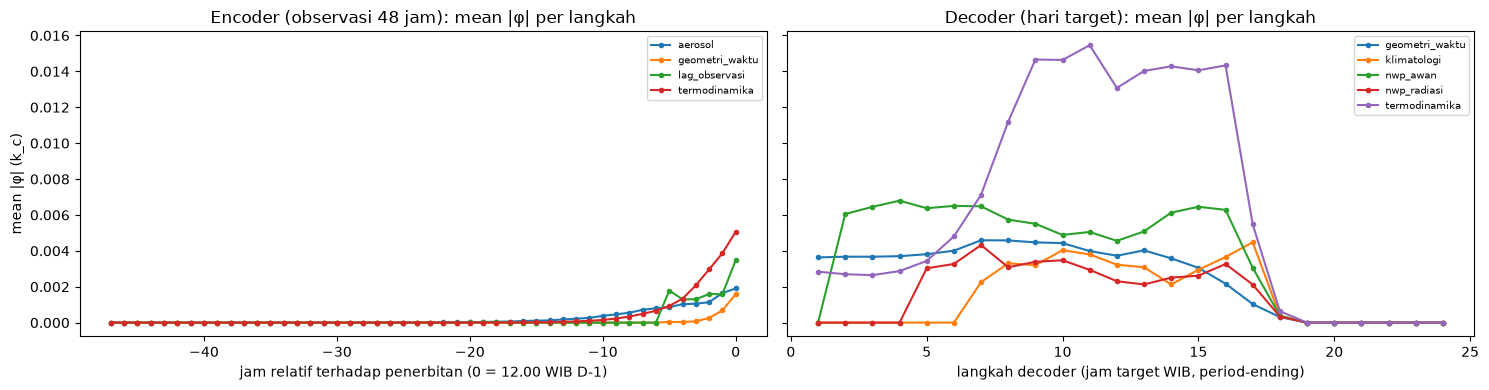


Ringkas untuk decisions.md:
- 2026-11-27 | Pelengkap XAI LSTM (pasca-hasil): GradientExplainer (latar 100 hari latih, 500 titik, 5 seed, 200 sampel sama). DeepExplainer: GAGAL uji aditivitas (AssertionError); shap: unrecognized nn.Module: LSTM (maks selisih Σφ 0.198). Peringkat GE: ['termodinamika', 'nwp_awan', 'geometri_waktu', 'klimatologi', 'nwp_radiasi', 'aerosol', 'lag_observasi']. ρ GE vs Shapley eksak: [0.536, 0.536]; ρ vs a priori: [-0.179, 0.0, 0.0]. | results/xai_ge_lstm_*.csv | Bab IV.4


In [12]:
# 8.4 Tingkat fitur/kanal + profil waktu
ch_imp = GE_MEAN.abs().mean(); ch_imp = (ch_imp / ch_imp.sum()).sort_values(ascending=False)
ch_tab = pd.DataFrame({"porsi": ch_imp.round(3), "kelompok": ch_imp.index.map(CH_GROUP)})
print("Kanal LSTM teratas (porsi mean |φ|, GradientExplainer):"); display(ch_tab.head(12))
ch_tab.to_csv(RES / "xai_ge_lstm_channel_importance.csv")

phs_m = np.mean([np.abs(p) for p, _ in GE_RAW.values()], axis=0).mean(axis=0)   # [48, kanal enc]
pht_m = np.mean([np.abs(q) for _, q in GE_RAW.values()], axis=0).mean(axis=0)   # [24, kanal dec]
enc_t = pd.DataFrame(phs_m, index=np.arange(-(XS.shape[1] - 1), 1), columns=SEQ_NAMES).T.groupby(lambda c: CH_GROUP[c]).sum().T
dec_t = pd.DataFrame(pht_m, index=np.arange(1, XT.shape[1] + 1), columns=TGT_NAMES).T.groupby(lambda c: CH_GROUP[c]).sum().T
fig, axs = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
enc_t.plot(ax=axs[0], marker=".")
axs[0].set(title="Encoder (observasi 48 jam): mean |φ| per langkah", xlabel="jam relatif terhadap penerbitan (0 = 12.00 WIB D-1)", ylabel="mean |φ| (k_c)")
dec_t.plot(ax=axs[1], marker=".")
axs[1].set(title="Decoder (hari target): mean |φ| per langkah", xlabel="langkah decoder (jam target WIB, period-ending)")
for a in axs: a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "xai_ge_lstm_temporal.png", dpi=150, bbox_inches="tight"); plt.show()
enc_t.round(5).to_csv(RES / "xai_ge_lstm_temporal_encoder.csv"); dec_t.round(5).to_csv(RES / "xai_ge_lstm_temporal_decoder.csv")

rk = ge_cmp["peringkat"]["GE sum|φ| kanal"].sort_values()
print(f"\nRingkas untuk decisions.md:\n- {pd.Timestamp.today():%Y-%m-%d} | Pelengkap XAI LSTM (pasca-hasil): GradientExplainer "
      f"(latar 100 hari latih, {NSAMP} titik, {N_GE_SEEDS} seed, 200 sampel sama). DeepExplainer: {DEEP_STATUS}"
      f"{'' if np.isnan(DEEP_GAP) else f' (maks selisih Σφ {DEEP_GAP:.3f})'}. Peringkat GE: {list(rk.index)}. "
      f"ρ GE vs Shapley eksak: {ge_agree.loc[ge_agree['pembanding'] == 'Shapley kelompok eksak', 'rho'].iloc[0]}; "
      f"ρ vs a priori: { {r.metode: r.rho for r in ge_agree[ge_agree['pembanding'] == 'a priori'].itertuples()} }. | results/xai_ge_lstm_*.csv | Bab IV.4")